# Машинное обучение, ФКН ВШЭ

# Практическое задание 8. Обучение без учителя.

## Общая информация
Дата выдачи: 20.09.2026

Мягкий дедлайн: 04.10.2026 23:59 MSK

Жёсткий дедлайн: 11.10.2026 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи).

Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-08-Username.ipynb

Username — ваша фамилия на латинице

## О задании

В этом задании мы посмотрим на несколько алгоритмов кластеризации и применим их к географическим и текстовым данным. Также мы подробно остановимся на тематическом моделировании текстов, задаче обучения представлений и в каком-то смысле поработаем с semi-supervised learning.



In [1]:
import pandas as pd
import numpy as np

np.random.seed(0xFFFFFFF)

In [ ]:
TF-IDF + Logistic Regression: 0.989
LDA + Logistic Regression:    0.930
K-Means + Logistic Regression: 0.849

**Задание 0 (1e-100 балла)**. Какие ожидания от курса?

Надеюсь немного лучше понять МО, так как на МО-1 я не прям сильно кайфанул от ML, надеюсь здесь я обрету некоторые более зрелые знания, больше проникнусь всем этим

## Часть 1. Кластеризация автобусных остановок

В этом задании мы сравним разные алгоритмы кластеризации для данных об автобусных остановках Москвы.

**Задание 1.1 (1 балл).** Реализуйте алгоритм спектральной кластеризации, который упоминался на лекции. Для этого разберитесь с кодом шаблона, данного ниже, и допишите недостающую функцию. Напомним, что для графа с матрицей смежности $W = \{w_{ij}\}_{i, j = 1 \dots \ell}$ лапласиан определяется как:

$$
L = D - W,
$$

где $D = \text{diag}(d_1, ..., d_{\ell}), d_i = \sum_{j=1}^{\ell} w_{ij}$.

In [3]:
from sklearn.base import ClusterMixin
from sklearn.cluster import KMeans


class GraphClustering(ClusterMixin):
    def __init__(self, n_clusters=8, n_components=None, **kwargs):
        '''
        Spectral clustering algorithm
        param n_clusters: number of clusters to form
        param n_components: number of eigenvectors to use
        '''

        if n_components is None:
            n_components = n_clusters

        self.n_components = n_components
        self.kmeans = KMeans(n_clusters=n_clusters, **kwargs)

    def fit_predict(self, X, y=None):
        '''
        Perform spectral clustering from graph adjacency matrix
        and return vertex labels.
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, ) - vertex labels
        '''

        eigenvectors = self._generate_eigenvectors(X)
        labels = self.kmeans.fit_predict(eigenvectors[:, 1:])
        return labels

    def _generate_eigenvectors(self, X):
        '''
        Compute eigenvectors for spectral clustering
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, n_components) - eigenvectors
        '''

        X = np.asarray(X, dtype=float)

        D = np.diag(np.sum(X, axis=1))
        L = D - X

        eigenvalues, eigenvectors = np.linalg.eigh(L)
        order = np.argsort(eigenvalues)
        eigenvectors = eigenvectors[:, order]

        return eigenvectors[:, :self.n_components]

Перед тем, как переходить к следующему заданию, протестируйте свое решение.

In [4]:
n_blocks, n_vertices = 10, 1000
block_vertices = n_vertices // n_blocks

X = np.zeros((n_vertices, n_vertices))
for i in range(0, n_vertices, block_vertices):
    X[i:i + block_vertices, i:i + block_vertices] = np.sqrt(i + 1)

graph_clustering = GraphClustering(n_clusters=n_blocks)
labels = graph_clustering.fit_predict(X)

true_labels = np.zeros(n_vertices, dtype=np.int32)
for i in range(0, n_vertices, block_vertices):
    true_labels[i:i + block_vertices] = labels[i]

assert labels.shape == (n_vertices, )
assert np.all(np.bincount(labels) == np.full(n_blocks, block_vertices))
assert np.all(labels == true_labels)

Теперь можем приступить к работе с реальными данными. Скачайте файл с данными об остановках общественного транспорта **в формате .xlsx** по [ссылке](https://disk.yandex.ru/i/J0HlcDXd_KyIeg). Для удобства визуализации мы будем работать только с остановками в ЦАО.

In [5]:
data = pd.read_excel('transport.xlsx')
data = data[data.AdmArea_en == "Czentral`ny'j administrativny'j okrug"]
data = data.reset_index()
data.head()

,index,ID_en,Name_en,Longitude_WGS84_en,Latitude_WGS84_en,Street_en,AdmArea_en,District_en,RouteNumbers_en,StationName_en,Direction_en,Pavilion_en,OperatingOrgName_en,EntryState_en,global_id,geoData
0,278,347,"«2-й Лесной пер.», улица Бутырский Вал (347)",37.586584,55.782106,улица Бутырский Вал,Czentral`ny'j administrativny'j okrug,Tverskoj rajon,АТ18; А12; АТ56; АТ78,2-й Лесной пер.,NaN,да,ГУП «Мосгортранс»,active,889085436,NaN
1,279,349,"«Ул. Сущевский Вал», Новослободская улица (349)",37.590714,55.790630,Новослободская улица,Czentral`ny'j administrativny'j okrug,Tverskoj rajon,АТ47; АМ10; АТ3; АТ56; АТ78,Ул. Сущевский Вал,NaN,да,ГУП «Мосгортранс»,active,889085437,NaN
2,355,479,"«Стадион Лужники (южн.) (пос.)», улица Лужники...",37.565972,55.714265,улица Лужники,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Стадион Лужники (южн.) (пос.),NaN,да,ГУП «Мосгортранс»,active,889085549,NaN
3,356,480,"«Спортзал Дружба», Лужнецкая набережная (480)",37.570191,55.712504,Лужнецкая набережная,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Спортзал Дружба,NaN,да,ГУП «Мосгортранс»,active,889085550,NaN
4,357,481,"«Лужнецкая наб.», Лужнецкая набережная (481)",37.574559,55.713770,Лужнецкая набережная,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Лужнецкая наб.,NaN,да,ГУП «Мосгортранс»,active,889085551,NaN


Воспользуемся библиотекой `folium` для визуализации данных.

In [6]:
import folium

map = folium.Map([55.75215, 37.61819], zoom_start=12)
for id, row in data.iterrows():
    folium.Circle([row.Latitude_WGS84_en, row.Longitude_WGS84_en],
                  radius=10).add_to(map)
map

**Задание 1.2 (1 балл).** Попробуем построить граф, в котором вершинами будут остановки. Как вы уже могли заметить, для каждой остановки указаны номера маршрутов, проходящих через неё. Логично соединить ребрами соседние остановки каждого маршрута. Однако мы не знаем, в каком порядке автобусы объезжают остановки. Но мы можем применить эвристический алгоритм, который восстановит нам порядок маршрутов:

* Для каждого маршрута выделим список всех остановок, через которые он проходит.
* Выберем начальную остановку маршрута как точку, наиболее удаленную от всех остальных остановок этого маршрута.
* Каждую следующую точку маршрута будем выбирать как самую близкую из оставшихся точек (не включенных в маршрут ранее).

Фактически, у нас получается жадное решение задачи коммивояжера. Когда мы отсортировали маршруты, можем построить по ним граф. Будем строить его по таким правилам:

* Между двумя остановками будет ребро, если они являются соседними хотя бы на одном маршруте. Вес ребра равен числу маршрутов, на которых остановки являются соседними.
* В графе не будет петель (то есть у матрицы смежности будет нулевая диагональ).

Реализуйте предложенный способ построения графа. Для этого рекомендуется воспользоваться шаблонами, приведенными ниже.

In [7]:
def get_routes(data):
    '''
    Accumulate routes from raw data
    param data: pd.DataFrame - public transport stops data
    return: dict - unsorted stops ids for each route,
                   e.g. routes['A1'] = [356, 641, 190]
    '''
    routes = {}
    for _, row in data.iterrows():
        routenums = row['RouteNumbers_en'].split('; ')
        for route in routenums:
            routes.setdefault(route, []).append(row['ID_en'])
    return routes


def sort_routes(data, routes):
    '''
    Sort routes according to the proposed algorithm
    param data: pd.DataFrame - public transport stops data
    param routes: dict - unsorted stops ids for each route
    return: dict - sorted stops ids for each route
    '''
    coords = data.set_index('ID_en')[['Latitude_WGS84_en', 'Longitude_WGS84_en']]
    sorted_routes = {}

    for route, stop_ids in routes.items():
        ost = list(set(stop_ids))
        if len(ost) < 2:
            sorted_routes[route] = ost
            continue

        points = coords.loc[ost].to_numpy(dtype=float)
        distances = np.linalg.norm(points[:, None] - points[None, :], axis=2) # Интересный способ, раньше не знал. Типо оба массива расширяются до (N, N, 2), и потом уже считаются попарные расстояния.
        current_index = int(np.argmax(distances.sum(axis=1)))
        ordered = [ost.pop(current_index)]

        while ost:
            current_point = coords.loc[ordered[-1]].to_numpy(dtype=float)
            next_index = int(np.argmin(
                np.linalg.norm(coords.loc[ost].to_numpy(dtype=float) - current_point, axis=1) # Ближайщую точку
            ))
            ordered.append(ost.pop(next_index)) # Забираем ближайшую точку и добавляем к маршруту

        sorted_routes[route] = ordered

    return sorted_routes


def get_adjacency_matrix(data, sorted_routes):
    '''
    Compute adjacency matrix for sorted routes
    param data: pd.DataFrame - public transport stops data
    param sorted_routes: dict - sorted stops ids for each route
    return: (n_samples, n_samples) - graph adjacency matrix
    '''
    stop_nums = {
        stop_id: i
        for i, stop_id in enumerate(data['ID_en']) # Просто нумеруем остановки
    }
    adjacency_matrix = np.zeros((len(data), len(data)), dtype=int)

    for route in sorted_routes.values():
        for i in range(len(route) - 1):
            first_pos = stop_nums[route[i]]
            second_pos = stop_nums[route[i + 1]]
            if first_pos != second_pos:
                adjacency_matrix[first_pos, second_pos] += 1
                adjacency_matrix[second_pos, first_pos] += 1

    return adjacency_matrix

In [8]:
routes = get_routes(data)
sorted_routes = sort_routes(data, routes)
adjacency_matrix = get_adjacency_matrix(data, sorted_routes)

Проверим, что маршруты получились адекватными. Для этого нарисуем их на карте.

In [9]:
map = folium.Map([55.75215, 37.61819], zoom_start=12)
coordinates = data.set_index('ID_en') # Тут поменял на эти индексы, так как так это логичнее
for route_id in np.random.choice(list(sorted_routes.keys()), size=5):
    coords = coordinates.loc[
        sorted_routes[route_id],
        ['Latitude_WGS84_en', 'Longitude_WGS84_en']
    ].values.tolist()
    folium.vector_layers.PolyLine(coords).add_to(map)

map

**Задание 1.3 (0 баллов)**. Реализуйте функцию `draw_clustered_map`, которая рисует карту центра Москвы с кластерами остановок, раскрашенными в разные цвета.

In [10]:
def draw_clustered_map(data, labels):
    '''
    Create map with coloured clusters
    param data: pd.DataFrame - public transport stops data
    param labels: (n_samples, ) - cluster labels for each stop
    return: folium.Map - map with coloured clusters
    '''
    all_colours = [
        'red', 'blue', 'green', 'purple', 'orange', 'darkred', 'lightblue',
        'darkgreen', 'cadetblue', 'pink', 'lightgreen', 'darkpurple',
        'beige', 'black', 'lightred', 'gray'
    ]

    cluster_ids = sorted(np.unique(labels))
    colors = { # Назначаю цвета кластерам
        cluster_id: 'gray' if cluster_id == -1 else all_colours[index % len(all_colours)]
        for index, cluster_id in enumerate(cluster_ids)
    }

    clustered_map = folium.Map([55.75215, 37.61819], zoom_start=12)
    for (_, row), label in zip(data.iterrows(), labels):
        folium.CircleMarker(
            location=[row['Latitude_WGS84_en'], row['Longitude_WGS84_en']],
            radius=5,
            color=colors[label],
            fill=True,
            fill_color=colors[label],
            fill_opacity=0.8
        ).add_to(clustered_map)

    return clustered_map

**Задание 1.4 (1.5 балла)**. Примените алгоритмы кластеризации и подберите гиперпараметры так, чтобы кластеры получились осмысленными (нет такого, что все принадлежит одному кластеру или большая часть точек это шум):
- `sklearn.clustering.KMeans` - `n_clusters`
- `sklearn.clustering.DBSCAN` - `eps`
- ваш `SpectralClustering` - `n_clusters` и `n_components`

Для ряда алгоритмов, в частности DBSCAN, подобрать оптимальные параметры может быть ой, как непросто. Чтобы помочь сохранить нервные клетки рекомендуется пользоваться метриками Intrinsic Evaluation для кластеризации. Для каждого алгоритма скорее всего придется брать разные метрики, а может быть оптимизировать сразу несколько.

Ваша задача - выбрать подходящую метрику, можно взять что-то из списка ниже, можно спросить у гугла. Применить GridSearch, `optuna` или `hyperopt` и желательно завернуть отбор параметров в функцию, пригодится далее

1. $
   \text{Calinski-Harabasz Index} \in [0, \inf] = \frac{\sum_{i=1}^k BCSS_i/(k-1)}{\sum_{i=1}^k WCSS_i/(n-k)} = \frac{\sum_{i=1}^k n_i \| \mathbf{c}_i - \mathbf{c} \|^2/(k-1)}{\sum_{i=1}^k \sum_{\mathbf{x} \in C_i} \|\mathbf{x} - \mathbf{c}_i\|^2/(n-k)} \rightarrow max
   $
   - Отношение 1) расстояния от центра кластера до центра всех данных к 2) расстоянию от центра кластера до точки
   - Чем однороднее и дальше друг от друга кластеры, тем лучше
2. $
   \text{Silhouette Score} \in [0, 1] = \sum_i \frac{b_i - a_i}{\max(a_i, b_i)} \rightarrow max
   $
   - $a_i$ - среднее расстояние до точек внутри своего кластера
   - $b_i$ - среднее расстояние до точек из ближайшего кластера
   - Если в своем кластере точки близко - кластер плотный, идеальный вариант, скор равен 1, если свой кластер совпадает с соседним - кластеры неразделимы, скор равен нулю
   - Чем однороднее и разделимее кластеры, тем лучше
3. $\text{Davies-Bouldin Index} \in [0, inf] = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \left( \frac{WCSS_i + WCSS_j}{d(c_i, c_j)} \right) \rightarrow min $
   - Отношение внутрикластерных расстояний к межкластерному расстоянию между двумя центрами
   - Если кластеры далеко друг от друга, но при этом однородные, скор наименьший
3. $\text{Elbow Method}$ - последовательное сравнение $WCSS$ из пункта 1 для разного числа параметров. Если уменьшение меньше определенного порога - останавливаемся, считаем это значение оптимальным

In [11]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


def clustering_objective(
    model,
    features,
    metric_features=None,
    min_clusters=3,
    max_clusters=20,
    max_noise_ratio=0.3
):
    labels = model.fit_predict(features)
    metric_features = features if metric_features is None else metric_features
    noise_ratio = np.mean(labels == -1)
    valid = labels != -1
    cluster_count = len(np.unique(labels[valid]))

    if noise_ratio > max_noise_ratio or not min_clusters <= cluster_count <= max_clusters:
        return -np.inf, labels

    return silhouette_score(metric_features[valid], labels[valid]), labels


coordinate_features = data[
    ['Latitude_WGS84_en', 'Longitude_WGS84_en']
].to_numpy(dtype=float)
scaled_features = StandardScaler().fit_transform(coordinate_features) # Делаю на всякий случай, + в DBSCAN легче думать об eps будет когда фичи от 0 до 1.

best_models = {}

kmeans_candidates = []
for n_clusters in range(3, 13):
    model = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
    score, labels = clustering_objective(model, scaled_features)
    kmeans_candidates.append((score, n_clusters, labels))
score, n_clusters, labels = max(kmeans_candidates)
best_models['KMeans'] = (score, {'n_clusters': n_clusters}, labels)

spectral_candidates = []
for n_clusters in range(4, 13):
    for n_components in [4, 5, 6, 8, 10, 12, 15, 20]:
        if n_components < n_clusters:
            continue
        model = GraphClustering(
            n_clusters=n_clusters,
            n_components=n_components,
            random_state=0,
            n_init=10
        )
        score, labels = clustering_objective(
            model,
            adjacency_matrix,
            metric_features=scaled_features,
        )
        spectral_candidates.append((score, n_clusters, n_components, labels))
score, n_clusters, n_components, labels = max(spectral_candidates)
best_models['Spectral'] = (
    score,
    {'n_clusters': n_clusters, 'n_components': n_components},
    labels
)

dbscan_candidates = []
for min_samples in [3, 5, 8, 10, 15]:
    for eps in np.linspace(0.05, 1.0, 39):
        model = DBSCAN(eps=eps, min_samples=min_samples)
        score, labels = clustering_objective(model, scaled_features)
        dbscan_candidates.append((score, eps, min_samples, labels))
score, eps, min_samples, labels = max(dbscan_candidates)
best_models['DBSCAN'] = (
    score,
    {'eps': eps, 'min_samples': min_samples},
    labels
)

Визуализируйте результат кластеризации с помощью функции `draw_clustered_map`.

In [12]:
from IPython.display import display

for algorithm, (score, parameters, labels) in best_models.items():
    print(f'{algorithm}: {parameters}, silhouette={score:.3f}')
    print(f'{len(np.unique(labels[labels != -1]))} clusters, '
          f'{np.sum(labels == -1)} noise points')
    display(draw_clustered_map(data, labels))

KMeans: {'n_clusters': 6}, silhouette=0.437
6 clusters, 0 noise points


Spectral: {'n_clusters': 6, 'n_components': 15}, silhouette=0.043
6 clusters, 0 noise points


DBSCAN: {'eps': np.float64(0.22499999999999998), 'min_samples': 15}, silhouette=0.328
10 clusters, 86 noise points


**Вопрос:** Чем отличаются разбиения на кластеры, получаемые разными алгоритмами? Какие плюсы и минусы есть у каждого алгоритма? Какой алгоритм кажется вам наиболее подходящим для кластеризации остановок?

**Ответ:**

KMeans разделяет объекты на заданное число компактных кластеров. Тут получаются такие как бы облачка из точек. Лучший результат: 6 кластеров, silhouette = 0.437, шумовых точек нет. Метод простой, быстрый и классный, но требует заранее указать число кластеров и вроде чувствителен к выбросам (тут их нет).

Спектральная кластеризация учитывает связи между объектами через граф структуру. Лучшие параметры: n_clusters = 6, n_components = 15, silhouette = 0.043. По этой метрике в данный момент он проиграл, но в целом он наверное может находить сложные зависимости (так как учитывает маршруты). Видимо он выделил таки основные направления как ездят автобусы (типо красное показывает, что многие из них наверное едут сверху вниз типо итд). Возможно, если бы получше сказали цель для чего мы кластеризуем, то можно было эту кластеризацию лучше применить для конкретной цели

DBSCAN объединяет близко расположенные точки и выделяет шум. Лучший результат: 10 кластеров, silhouette = 0.328, 86 шумовых точек. Преимущество - не нужно заранее задавать число кластеров. Минус — есть другие параметры, которые нужно задавать (и к ним он достаточно чувствителен).

Наиболее подходящим мне кажется здесь является KMeans, поскольку он показал наибольший коэффициент силуэта и мне нравится как выглядит.

Может стояло рассмотреть и другие метрики, но я выбрал эту, так как она достаточно мощная. Похоже, для спектральной кластеризации она не особо подходит.



## Часть 2. Тематическое моделирование текстов

В этой части мы познакомимся с одной из самых популярных задач обучения без учителя &mdash; с задачей тематического моделирования текстов. Допустим, нам доступна некоторая коллекция документов без разметки, и мы хотим автоматически выделить несколько тем, которые встречаются в документах, а также присвоить каждому документу одну (или несколько) тем. Фактически, мы будем решать задачу, похожую на кластеризацию текстов: отличие в том, что нас будет интересовать не только разбиение текстов на группы, но и выделение ключевых слов, определяющих каждую тему.

Мы будем работать с новостными статьями BBC за 2004-2005 годы. Скачайте данные по [ссылке](https://www.kaggle.com/hgultekin/bbcnewsarchive).

In [13]:
data = pd.read_csv('bbc-news-data.csv', sep='\t')
data.sample(5)

,category,filename,title,content
2079,tech,256.txt,Poles play with GameBoy 'blip-pop',A group of artists in Poland has taken the ca...
2108,tech,285.txt,Format wars could 'confuse users',"Technology firms Sony, Philips, Matsushita an..."
956,politics,061.txt,Assembly ballot papers 'missing',Hundreds of ballot papers for the regional as...
18,business,019.txt,India widens access to telecoms,India has raised the limit for foreign direct...
214,business,215.txt,SEC to rethink post-Enron rules,The US stock market watchdog's chairman has s...


Как вы могли заметить, данные уже содержат разметку по тематике (колонка category). В этой части мы забудем, что она есть, и будем работать только с текстовыми данными. Проведем предобработку текста, состоящую из следующих пунктов:

* Объединим заголовок и содержание статьи в одно поле.
* Приведем текст к нижнему регистру, разобьем его на токены.
* Оставим только буквенные слова (удалив, таким образом, пунктуацию и числа).
* Применим лемматизацию.
* Удалим стоп-слова.


In [14]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [15]:
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('stopwords')

stop_words = set(stopwords.words('english') + ['ha', 'wa', 'say', 'said'])
lemmatizer = WordNetLemmatizer()

[nltk_data] Error loading punkt: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>
[nltk_data] Error loading wordnet: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>
[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>


In [16]:
def preprocess(text):
    text = list(filter(str.isalpha, word_tokenize(text.lower())))
    text = list(lemmatizer.lemmatize(word) for word in text)
    text = list(word for word in text if word not in stop_words)
    return ' '.join(text)

In [17]:
data['raw_text'] = data.apply(lambda row: row.title + row.content, axis=1)
data['text'] = data.apply(lambda row: preprocess(row.raw_text), axis=1)

Для визуализации частот слов в текстах мы будем использовать [облака тегов](https://en.wikipedia.org/wiki/Tag_cloud).

In [18]:
from wordcloud import WordCloud

def draw_wordcloud(texts, max_words=1000, width=1000, height=500):
    wordcloud = WordCloud(background_color='white', max_words=max_words,
                          width=width, height=height)

    joint_texts = ' '.join(list(texts))
    wordcloud.generate(joint_texts)
    return wordcloud.to_image()

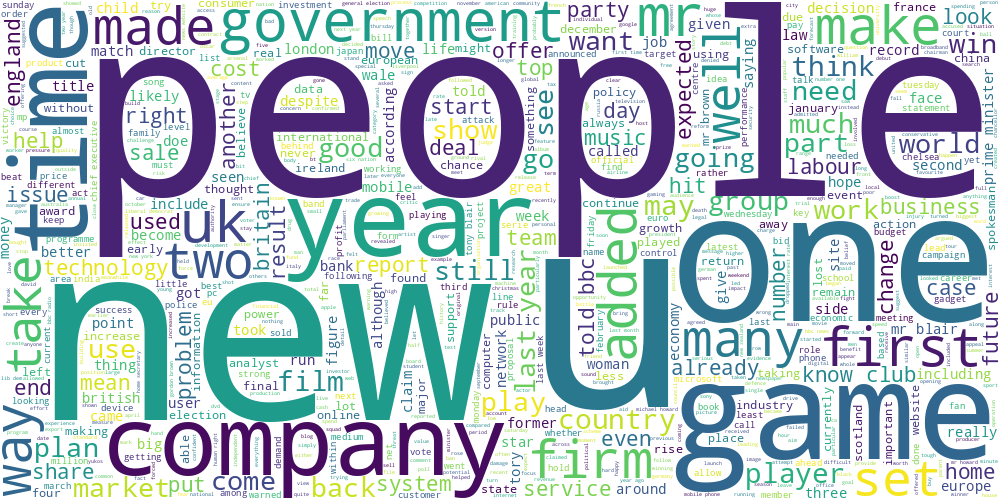

In [19]:
draw_wordcloud(data.text)

**Задание 2.1 (1 балл).** Обучите алгоритм K-Means на tf-idf представлениях текстов. При обучении tf-idf векторайзера рекомендуется отбрасывать редко встречающиеся слова, а также воздержитесь от использования N-грамм. Возьмите не очень большое число кластеров, чтобы было удобно интерпретировать получившиеся темы (например, `n_clusters` = 8). Постройте облака тегов для текстов из разных кластеров.

Количества документов по кластерам: {0: 194, 1: 344, 2: 360, 3: 202, 4: 443, 5: 219, 6: 93, 7: 370}
Cluster 0 (194 texts)


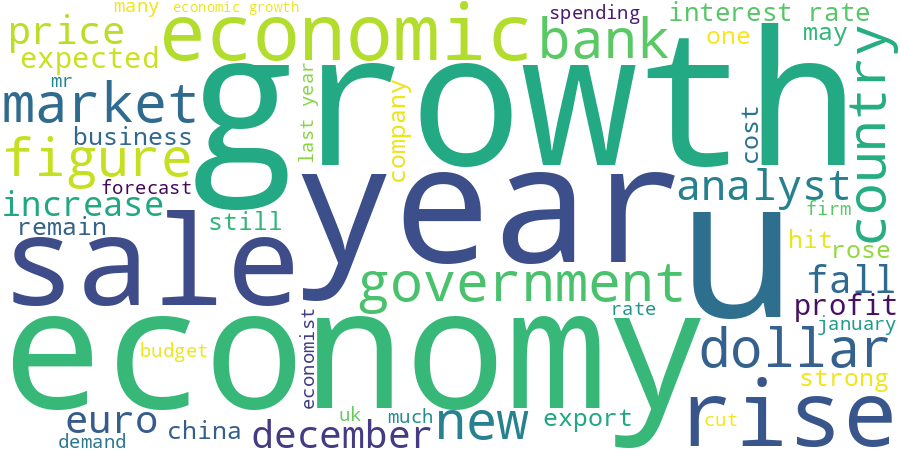

Cluster 1 (344 texts)


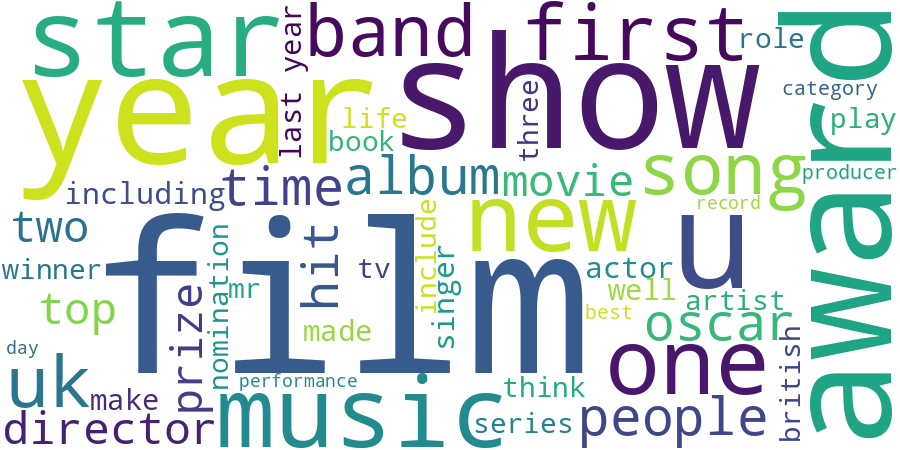

Cluster 2 (360 texts)


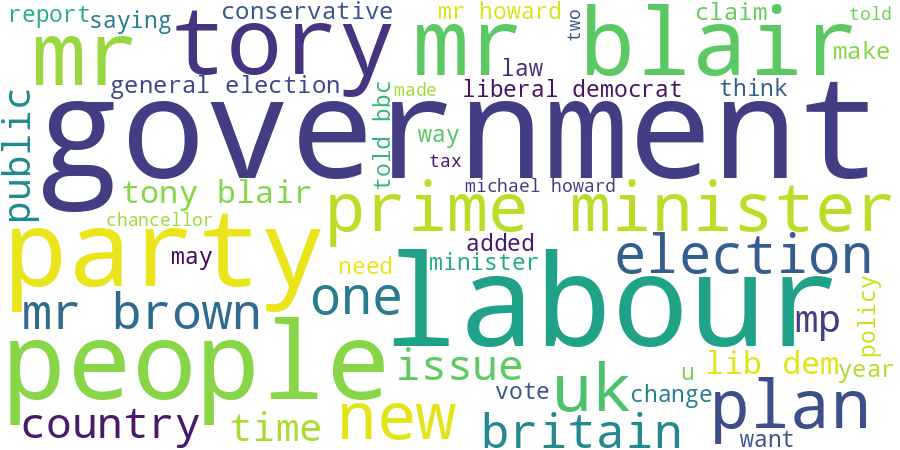

Cluster 3 (202 texts)


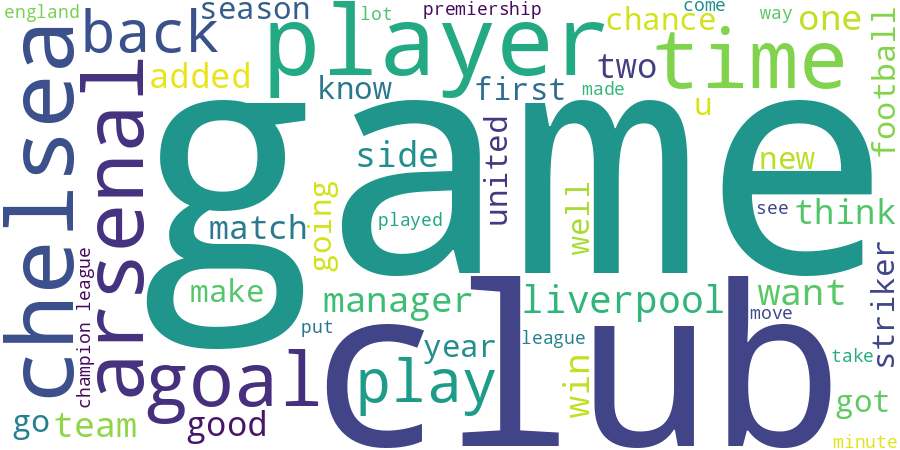

Cluster 4 (443 texts)


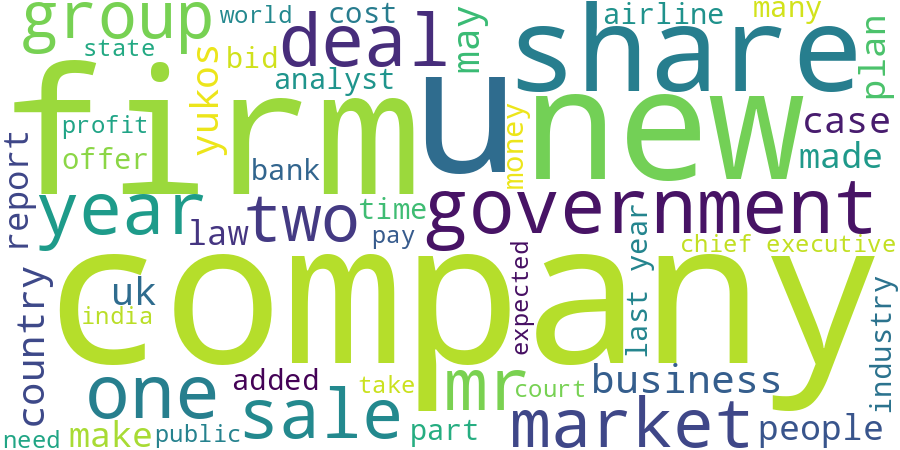

Cluster 5 (219 texts)


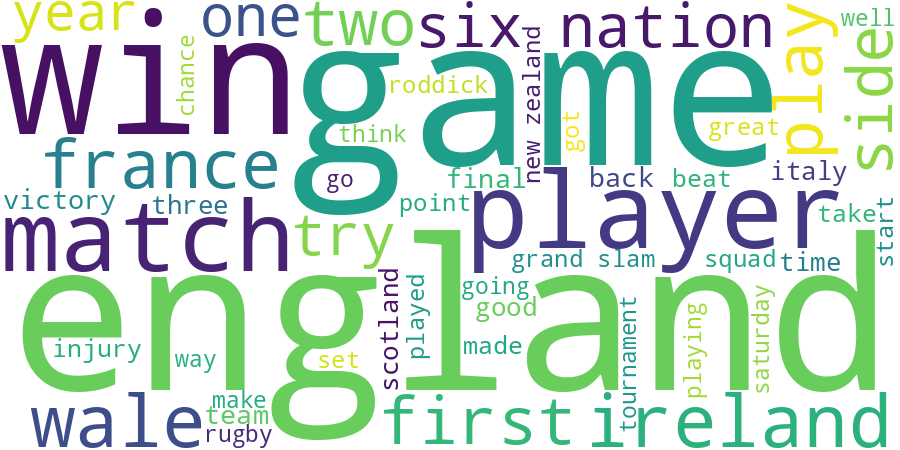

Cluster 6 (93 texts)


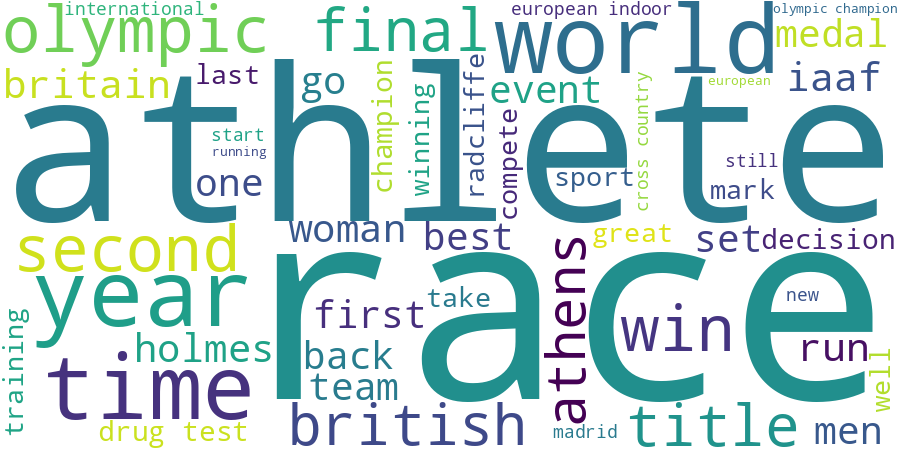

Cluster 7 (370 texts)


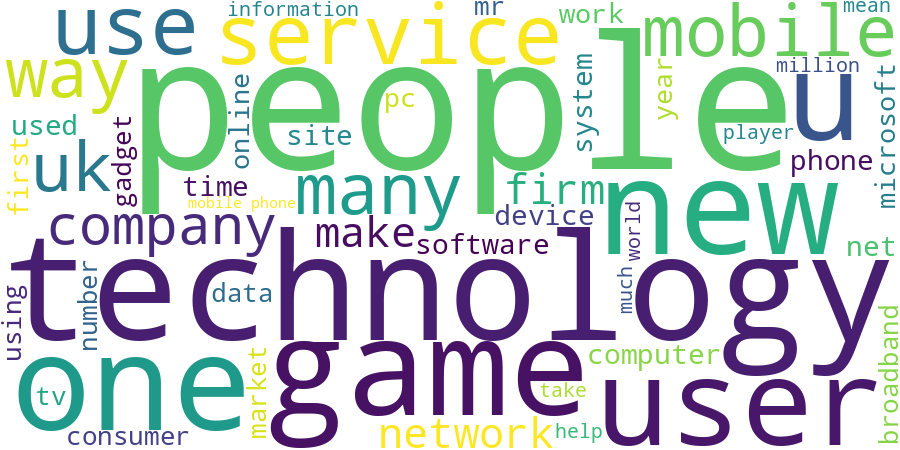

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from IPython.display import display

tfidf_vectorizer = TfidfVectorizer(
    min_df=3, # отбрасываю совсем редкие слова
    ngram_range=(1, 1), # по одному слову
    sublinear_tf=True # С этой настройкой как будто немного получше работает
)
tfidf_matrix = tfidf_vectorizer.fit_transform(data['text'])

n_clusters = 8
kmeans_text = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
text_labels = kmeans_text.fit_predict(tfidf_matrix)
data['cluster'] = text_labels

print('Количества документов по кластерам:', data['cluster'].value_counts().sort_index().to_dict())

for cluster_id in range(n_clusters):
    cluster_texts = data.loc[data['cluster'] == cluster_id, 'text']
    print(f"Cluster {cluster_id} ({len(cluster_texts)} texts)")
    display(draw_wordcloud(cluster_texts, max_words=50, width=900, height=450))

Получились ли темы интерпретируемыми? Попробуйте озаглавить каждую тему.

**Ответ:**

В целом темы да. Но где-то были и проблемы. Например, 0 и 4 похожи, а также 3 и 5. Но вроде разделил как-то.

0. Экономика, рынки
1. Шоу-бизнес
2. Политика
3. Клубный футбол Англии
4. Бизнес
5. Международные спортивные турниры
6. Олимпиада
7. Технологии

**Задание 2.2 (0.5 балла).** Попробуем другой способ выделить ключевые слова для каждой темы. Помимо непосредственного разбиения объектов алгоритм K-Means получает центр каждого кластера. Попробуйте взять центры кластеров и посмотреть на слова, для которых значения соответствующих им признаков максимальны.

In [21]:
feature_names = tfidf_vectorizer.get_feature_names_out()
cluster_centers = kmeans_text.cluster_centers_

top_words_by_cluster = {}
for cluster_id, center in enumerate(cluster_centers):
    top_indices = center.argsort()[::-1][:20]
    print(f'Кластер {cluster_id}: {", ".join(feature_names[top_indices])}')


Кластер 0: growth, economy, rate, economic, price, rise, year, market, bank, figure, rose, quarter, dollar, month, analyst, economist, fall, sale, profit, export
Кластер 1: film, award, star, best, show, actor, year, band, music, oscar, album, singer, tv, director, actress, also, one, comedy, festival, song
Кластер 2: mr, labour, election, party, blair, tory, government, minister, would, leader, prime, people, conservative, howard, mp, brown, plan, secretary, chancellor, tony
Кластер 3: club, chelsea, game, player, league, arsenal, cup, goal, season, manager, football, bos, team, side, striker, united, liverpool, play, manchester, premiership
Кластер 4: company, firm, share, mr, year, would, market, deal, new, executive, business, group, financial, sale, government, also, could, chief, last, two
Кластер 5: game, match, england, win, player, ireland, injury, rugby, wale, open, coach, first, france, nation, victory, six, side, play, final, seed
Кластер 6: olympic, race, indoor, athens, a

Согласуются ли полученные слова с облаками тегов из прошлого задания?

**Ответ:** В целом да, согласуются. В начале идут по большей части слова характеризующие тему. Хотя тут есть и слова "growth", "mr", "people", которые стоят на первом месте и не прям характеризуют тему

**Задание 2.3 (1.5 балла).** В первой части мы сравнили три разных алгоритма кластеризации на географических данных. Проделаем то же самое для текстовых данных (в качестве признакого описания снова используем tf-idf). Получите три разбиения на кластеры с помощью алгоритмов K-Means, DBSCAN и спектральной кластеризации (на этот раз воспользуйтесь реализацией из `sklearn`). Для K-Means и спектральной кластеризации возьмите одинаковое небольшое число кластеров, подберите параметр `eps` метода DBSCAN так, чтобы получить приблизительно такое же число кластеров (подумайте, как это можно сделать)

Далее, обучите двухмерные t-SNE представления над tf-idf признаками текстов. Визуализируйте эти представления для каждого алгоритма, раскрасив каждый кластер своим цветом. Лучше всего расположить визуализации на одном графике на трех разных сабплотах. Не забудьте, что DBSCAN помечает некоторые точки как шумовые (можно раскрасить их в отдельный цвет).

KMeans: 7 clusters
Spectral: 7 clusters
DBSCAN: 6 clusters, eps=0.820, min_samples=13, 0.38 noise ratio, largest_fraction=0.47


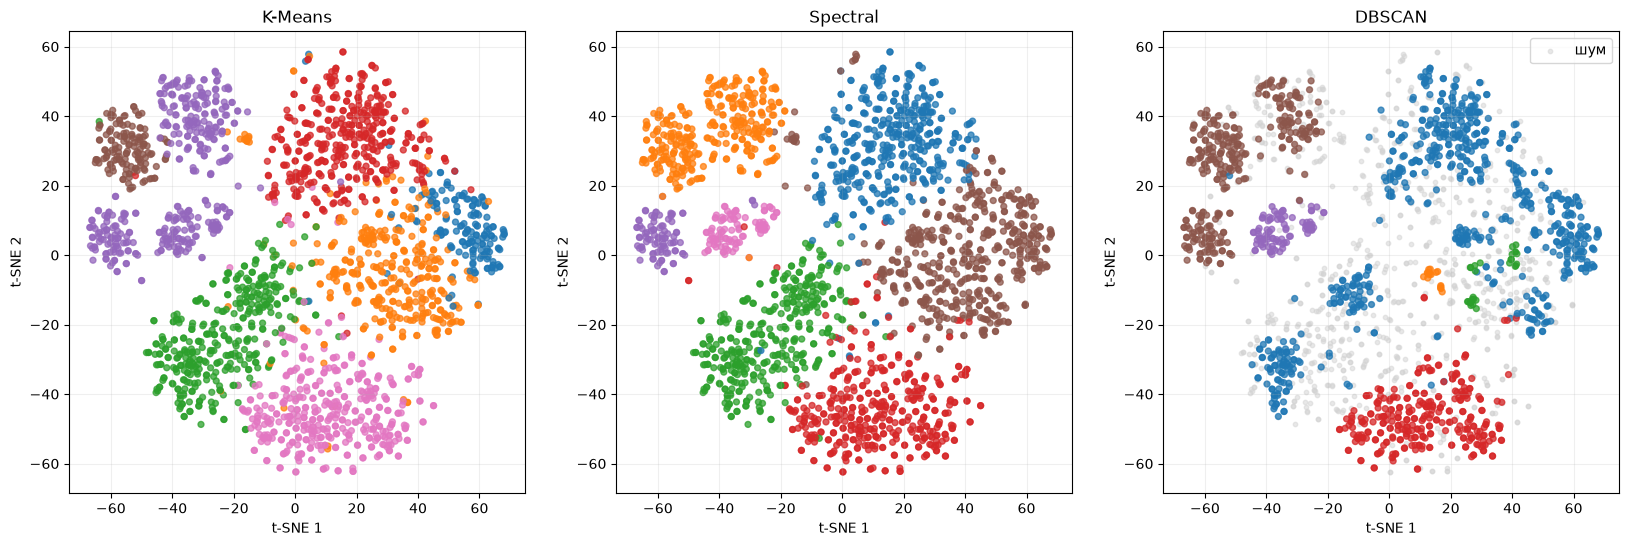

In [ ]:
from sklearn.cluster import DBSCAN, SpectralClustering
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

target_clusters = 7

kmeans_23 = KMeans(n_clusters=target_clusters, random_state=42, n_init=10)
labels_kmeans_23 = kmeans_23.fit_predict(tfidf_matrix)

spectral_23 = SpectralClustering(
    n_clusters=target_clusters,
    affinity='nearest_neighbors', # GitHub Copilot предложил эту настройку, и с ней реально лучше работает. Оно и логично, соединяемся с ближайшими текстами.
    random_state=42
)
labels_spectral_23 = spectral_23.fit_predict(tfidf_matrix)

dbscan_candidates = []
for eps in np.linspace(0.01, 1, 100):
    for min_samples in [5, 6, 8, 9, 10, 11, 12, 13, 14, 15]:
        labels = DBSCAN(
            eps=eps, min_samples=min_samples, metric='cosine' # говорят, что эта метрика лучше подходит для tf-idf
        ).fit_predict(tfidf_matrix)
        cluster_labels = labels[labels != -1]
        n_found = len(np.unique(cluster_labels))
        if n_found == 0:
            continue

        _, counts = np.unique(cluster_labels, return_counts=True)
        noise_fraction = np.mean(labels == -1)
        largest_fraction = counts.max() / len(cluster_labels)
        if target_clusters - 2 <= n_found <= target_clusters + 2 and noise_fraction <= 0.4:
            dbscan_candidates.append((largest_fraction, noise_fraction, eps, min_samples, labels, n_found))

largest_fraction, noise_fraction, best_eps, best_min_samples, labels_dbscan_23, dbscan_n_clusters = min(dbscan_candidates)

print(f'KMeans: {len(np.unique(labels_kmeans_23))} clusters')
print(f'Spectral: {len(np.unique(labels_spectral_23))} clusters')
print(f'DBSCAN: {dbscan_n_clusters} clusters, eps={best_eps:.3f}, min_samples={best_min_samples}, '
      f'{noise_fraction:.2f} noise ratio, largest_fraction={largest_fraction:.2f}')

tfidf_dense = tfidf_matrix.toarray()
tsne = TSNE(n_components=2, random_state=42)
tsne_coordinates = tsne.fit_transform(tfidf_dense)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
results_23 = [
    ('K-Means', labels_kmeans_23),
    ('Spectral', labels_spectral_23),
    ('DBSCAN', labels_dbscan_23)
]
for ax, (name, labels) in zip(axes, results_23):
    noise = labels == -1
    ax.scatter(*tsne_coordinates[noise].T, c='lightgray', s=10, alpha=0.5, label='шум')
    ax.scatter(*tsne_coordinates[~noise].T, c=labels[~noise], cmap='tab10',
               s=18, alpha=0.75, vmin=0, vmax=9)
    if noise.any():
        ax.legend(loc='upper right')
    ax.set_title(name)
    ax.set_xlabel('tsne 1')
    ax.set_ylabel('tsne 2')
    ax.grid(alpha=0.2)

plt.show()


Прокомментируйте получившиеся результаты. Какой баланс кластеров получился у разных методов? Соотносятся ли визуализации для текстов с визуализациями для географических данных?

**Ответ:**

Тут спектральная кластеризация справилась как будто лучше всех, по моему мнению. Баланс классов у спектральной и K-means примерно средний (классы похожи по величине), в DBSCAN немного хуже (2 слишком маленьких кластера и один слишком большой).
K-means и спектральная кластеризации хорошо справились: примерно равномерные классы и красивая картинка.
С DBSCAN у меня были проблемы (не мог добиться того, чтобы не было одного всеобъемлющего кластера и много малюсеньких). Но в итоге получилось как-то сделать (добавил ещё варианты для min_samples как минимум), но получилось много шума, к сожалению (0.38 вершин). При кластеризации я минимизировал largest_fraction (#точек в самом большом кластере / #всех точек), чтобы самый большой класс не был слишком большой.

С географической задачей это сложно сравнивать. Там мы рассматривали пространственную близость (по широте и долготе), а тут тексты. Тут строится всё по сходству слов и тематике документов. Да и визуализировали мы с помощью TSNE, а это просто инструмент чтобы как-то увидеть структуру данных, и как-то их сравнивать с координатами на карте сложно. Ну в целом свойства этих методов тут видны.



**Задание 2.4 (1.5 балла).** Обучите модель латентного размещения Дирихле. Не забудьте, что она работает с мешком слов, а не с tf-idf признаками. Придумайте, как превратить распределение тем для текста в номер его кластера. Возьмите параметр `n_components` в 2-3 раза больше, чем число кластеров для K-Means.

In [ ]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

bag_vectorizer = CountVectorizer(min_df=3, ngram_range=(1, 1))
bag_matrix = bag_vectorizer.fit_transform(data['text'])

lda = LatentDirichletAllocation(n_components=16, random_state=42)
document_topic_distribution = lda.fit_transform(bag_matrix)

# Я просто сделал, что номер кластера - это тема с наибольшей вероятностью (мне кажется это логично)
lda_clusters = document_topic_distribution.argmax(axis=1)
data['lda_topic'] = lda_clusters

feature_names_lda = bag_vectorizer.get_feature_names_out()
for topic_idx, topic_weights in enumerate(lda.components_):
    top_inds = topic_weights.argsort()[::-1][:15]
    print(f'Тема {topic_idx}: {", ".join(feature_names_lda[top_inds])}')

Тема 0: club, would, player, united, game, chelsea, league, football, time, liverpool, want, manager, team, cup, also
Тема 1: party, mr, would, election, eu, people, government, labour, vote, could, uk, council, general, european, issue
Тема 2: mobile, phone, people, service, digital, technology, camera, uk, one, handset, broadband, use, also, call, million
Тема 3: film, award, best, year, star, show, also, actor, director, oscar, tv, actress, movie, first, prize
Тема 4: company, firm, new, year, share, deal, would, also, world, market, could, business, country, people, one
Тема 5: people, user, technology, service, computer, software, firm, net, system, music, mr, network, site, internet, use
Тема 6: mr, blair, brown, howard, labour, poster, id, wenger, get, michael, told, minister, arsenal, like, campaign
Тема 7: england, ireland, game, wale, rugby, six, side, nation, player, france, scotland, try, new, coach, first
Тема 8: mr, would, lord, law, government, court, home, right, could,

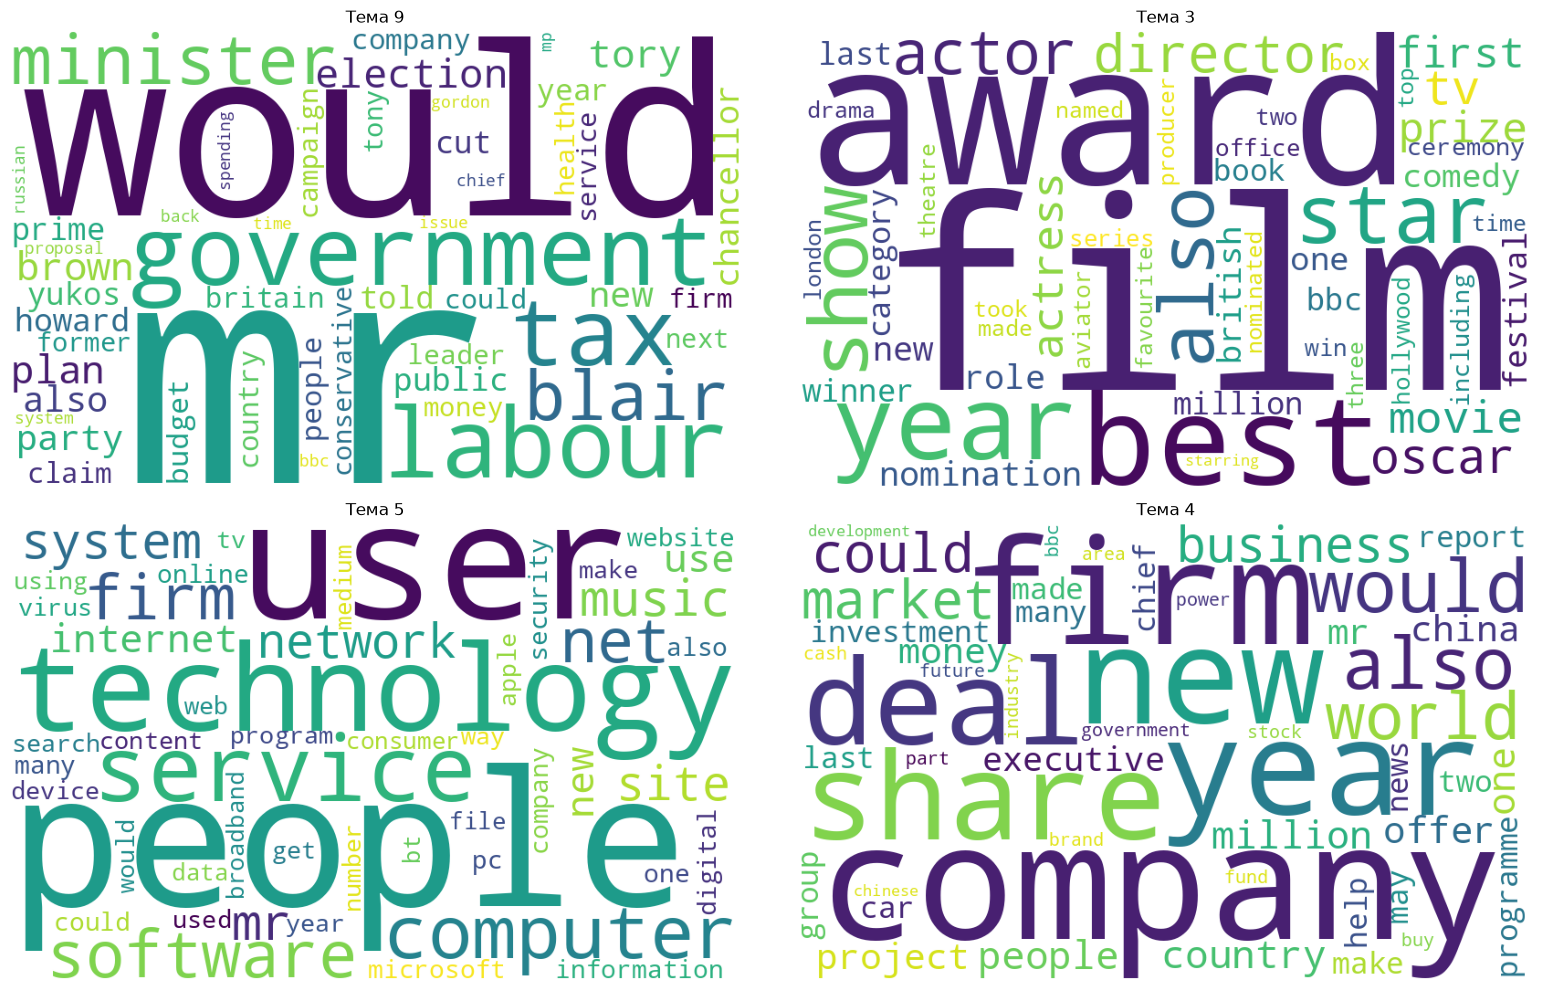

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

largest_topics = data['lda_topic'].value_counts().head(4).index
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, topic_ind in zip(axes.ravel(), largest_topics):
    topic_weights = lda.components_[topic_ind]
    frequencies = {
        feature_names_lda[i]: topic_weights[i]
        for i in topic_weights.argsort()[-50:]
    }
    cloud = WordCloud(
        width=800,
        height=500,
        background_color='white',
        random_state=42
    ).generate_from_frequencies(frequencies)
    ax.imshow(cloud)
    ax.set_title(f'Тема {topic_ind}')
    ax.axis('off')

plt.tight_layout()
plt.show()

Получились ли темы более узкими от такого нововведения? Постройте облака тегов для нескольких наиболее удачных тем.

**Ответ:**

Ну не знаю, сходу не очевидно. Но может будто больше стало больших слов и это возможно немного сужает тему. Напимер, на теме 3 как будто больше сконцентрировались именно на фильмах. В Теме 4 на бизнесовых сделках за год, нововведениях каких-то

## Часть 3. Transfer learning и Self-Supervised Learning для задачи классификации текстов

**Задание 3.1 (0.5 балла).** Вспомним, что у нас есть разметка для тематик статей. Попробуем обучить классификатор поверх unsupervised-представлений для текстов. Рассмотрите три модели:

* Логистическая регрессия на tf-idf признаках
* K-Means на tf-idf признаках + логистическая регрессия на расстояниях до центров кластеров
* Латентное размещение Дирихле + логистическая регрессия на вероятностях тем

Разделите выборку на обучающую и тестовую, замерьте accuracy на обоих выборках для всех трех моделей. Параметры всех моделей возьмите равными значениям по умолчанию.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data['text'],
    data['category'],
    test_size=0.2,
    random_state=42,
    stratify=data['category']
)

def print_accuracy(name, model, x_train, x_test):
    train_accuracy = accuracy_score(y_train, model.predict(x_train))
    test_accuracy = accuracy_score(y_test, model.predict(x_test))
    print(f'{name}: train accuracy={train_accuracy:.3f}, test accuracy={test_accuracy:.3f}')

# 1. Логистическая регрессия на tf-idf признаках
tfidf_31 = TfidfVectorizer()
x_train_tfidf = tfidf_31.fit_transform(X_train)
x_test_tfidf = tfidf_31.transform(X_test)

logreg_tfidf = LogisticRegression()
logreg_tfidf.fit(x_train_tfidf, y_train)
print_accuracy('TF-IDF + Logistic Regression', logreg_tfidf,
               x_train_tfidf, x_test_tfidf)

# 2. K-Means на tf-idf признаках + логистическая регрессия на расстояниях до центров кластеров
kmeans_31 = KMeans()
x_train_distances = kmeans_31.fit_transform(x_train_tfidf)
x_test_distances = kmeans_31.transform(x_test_tfidf)
logreg_kmeans = LogisticRegression()
logreg_kmeans.fit(x_train_distances, y_train)
print_accuracy('K-Means distances + Logistic Regression', logreg_kmeans,
               x_train_distances, x_test_distances)

# 3. Латентное размещение Дирихле + логистическая регрессия на вероятностях тем
bag_31 = CountVectorizer()
x_train_bow = bag_31.fit_transform(X_train)
x_test_bag = bag_31.transform(X_test)
lda_31 = LatentDirichletAllocation()
x_train_topics = lda_31.fit_transform(x_train_bow)
x_test_topics = lda_31.transform(x_test_bag)

logreg_lda = LogisticRegression()
logreg_lda.fit(x_train_topics, y_train)
print_accuracy('LDA + Logistic Regression', logreg_lda,
               x_train_topics, x_test_topics)

TF-IDF + Logistic Regression: train accuracy=0.997, test accuracy=0.989
K-Means distances + Logistic Regression: train accuracy=0.847, test accuracy=0.849
LDA + Logistic Regression: train accuracy=0.872, test accuracy=0.930


У какой модели получилось лучшее качество? С чем это связано?

**Ответ:**

Наилучшее качество на тестовой выборке показала первая модель. На втором месте модель с LDA, на третьем - модель с K-Means. Мне кажется это вполне логичным. Тут чем больше информации подаётся в LogReg, тем лучше получается. В первой модели подаются целые tf-idf вектора, в модели с LDA подаются распределения на темах (это немного меньше информации, так как сужается до определённого количества тем), в модели с K-means вообще подаётся просто расстояние до центра кластера, это ещё большее сжатие информации. Вот по этому, по моему мнению, и получилось такое качество.

**Задание 3.2 (1.5 балла).** Теперь просимулируем ситуацию слабой разметки, которая часто встречается в реальных данных. Разделим обучающую выборку в пропорции 5:65:30. Будем называть части, соответственно, размеченный трейн, неразмеченный трейн и валидация.

Все unsupervised-алгоритмы (векторайзеры и алгоритмы кластеризации) запускайте на всем трейне целиком (размеченном и неразмеченном, суммарно 70%), а итоговый классификатор обучайте только на размеченном трейне (5%). Подберите гиперпараметры моделей по качеству на валидации (30%), а затем оцените качество на тестовой выборке (которая осталась от прошлого задания). Не скромничайте при подборе числа кластеров, сейчас нас интересует не интерпретируемое разбиение выборки, а итоговое качество классификации.

In [101]:
X_work, X_test_32, y_work, y_test_32 = train_test_split(
    data['text'], data['category'], test_size=0.2, random_state=42,
    stratify=data['category']
)
X_train, X_val, y_train, y_val = train_test_split(
    X_work, y_work, test_size=0.3, random_state=42, stratify=y_work
)
X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
    X_train, y_train, test_size=65 / 70, random_state=42, stratify=y_train
)
X_all_train = pd.concat([X_labeled, X_unlabeled])


labeled_inds = X_all_train.index.get_indexer(X_labeled.index)

print(f'labeled={len(X_labeled)}, unlabeled={len(X_unlabeled)}, '
      f'validation={len(X_val)}, test={len(X_test_32)}')

# 1. Логистическая регрессия на tf-idf признаках
tfidf_32 = TfidfVectorizer()
x_all_tfidf = tfidf_32.fit_transform(X_all_train)
x_val_tfidf = tfidf_32.transform(X_val)
x_test_tfidf_32 = tfidf_32.transform(X_test_32)
tfidf_candidates = []
for C in [10.0, 12.0, 15.0, 17.0, 20.0, 30.0, 40.0, 60.0, 80.0]: # Подбираем степень регуляризации
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(x_all_tfidf[labeled_inds], y_labeled) # Можем обучать только на размеченных данных
    score = accuracy_score(y_val, model.predict(x_val_tfidf))
    tfidf_candidates.append((score, C, model))
best_tfidf_val, best_tfidf_C, best_tfidf_model = max(tfidf_candidates)
tfidf_test = accuracy_score(y_test_32, best_tfidf_model.predict(x_test_tfidf_32))

# 2. K-Means на tf-idf признаках + логистическая регрессия на расстояниях до центров кластеров
kmeans_candidates = []
for n_clusters in [16, 24, 32, 64, 80, 100]:
    kmeans = KMeans(n_clusters=n_clusters)
    x_all_dist = kmeans.fit_transform(x_all_tfidf)
    x_val_dist = kmeans.transform(x_val_tfidf)
    x_test_dist = kmeans.transform(x_test_tfidf_32)
    model = LogisticRegression()
    model.fit(x_all_dist[labeled_inds], y_labeled) # Можем обучать только на размеченных данных
    score = accuracy_score(y_val, model.predict(x_val_dist))
    kmeans_candidates.append((score, n_clusters, model, x_test_dist))
best_kmeans_val, best_kmeans_clusters, best_kmeans_model, best_kmeans_test = max(kmeans_candidates)
kmeans_test = accuracy_score(y_test_32, best_kmeans_model.predict(best_kmeans_test))

# 3. Латентное размещение Дирихле + логистическая регрессия на вероятностях тем
bag_32 = CountVectorizer()
x_all_bag = bag_32.fit_transform(X_all_train)
x_val_bag = bag_32.transform(X_val)
x_test_bag = bag_32.transform(X_test_32)
lda_candidates = []
for n_topics in [6, 8, 16, 24, 32]:
    lda = LatentDirichletAllocation(n_components=n_topics)
    x_all_topics = lda.fit_transform(x_all_bag)
    x_val_topics = lda.transform(x_val_bag)
    x_test_topics = lda.transform(x_test_bag)
    model = LogisticRegression()
    model.fit(x_all_topics[labeled_inds], y_labeled) # Можем обучать только на размеченных данных
    score = accuracy_score(y_val, model.predict(x_val_topics))
    lda_candidates.append((score, n_topics, model, x_test_topics))
best_lda_val, best_lda_topics, best_lda_model, best_lda_test = max(lda_candidates)
lda_test = accuracy_score(y_test_32, best_lda_model.predict(best_lda_test))

print(f'TF-IDF: C={best_tfidf_C}, validation={best_tfidf_val:.3f}, test={tfidf_test:.3f}')
print(f'K-Means: n_clusters={best_kmeans_clusters}, validation={best_kmeans_val:.3f}, test={kmeans_test:.3f}')
print(f'LDA: n_components={best_lda_topics}, validation={best_lda_val:.3f}, test={lda_test:.3f}')

labeled=89, unlabeled=1157, validation=534, test=445
TF-IDF: C=80.0, validation=0.903, test=0.917
K-Means: n_clusters=100, validation=0.648, test=0.665
LDA: n_components=16, validation=0.921, test=0.933


Как изменились результаты по сравнению с обучением на полной разметке? Сделайте выводы.

**Ответ:**

При слабой разметке качество ожидаемо ниже, чем в задании 3.1. Логистическая регрессия ведь обучается только на небольшой размеченной части (а unsupervised на всей train-выборке). Тут выиграл внезапно LDA: качество даже выше чем в предыдущем примере (на 0.003), но это видимо потому что мы тут подбираем гиперпараметры. Получается, когда размечено мало данных, то LDA лучше вытаскивает нужную информацию из имеющихся данных. А в TF-IDF некоторые ключевые слова в целом могут и не попасть в те 89 документов размеченных данных

## Бонус

**Задание 4 (0.5 балла)**. Разберитесь с semi-supervised методами, которые реализованы в `sklearn` и примените их к заданию 3.2. Получилось ли добиться лучшего качества? Сделайте выводы.

In [26]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 5 (0.5 балла)**. На занятиях мы обсуждали, что метрика [BCubed](https://www.researchgate.net/profile/Julio-Gonzalo-2/publication/225548032_Amigo_E_Gonzalo_J_Artiles_J_et_alA_comparison_of_extrinsic_clustering_evaluation_metrics_based_on_formal_constraints_Inform_Retriev_12461-486/links/0c96052138dbb99740000000/Amigo-E-Gonzalo-J-Artiles-J-et-alA-comparison-of-extrinsic-clustering-evaluation-metrics-based-on-formal-constraints-Inform-Retriev-12461-486.pdf) хорошо подходит для сравнения алгоритмов кластеризации, если нам известно настоящее разделение на кластеры (gold standard). Реализуйте подсчет метрики BCubed и сравните несколько алгоритмов кластеризации на текстовых данных из основного задания. В качестве gold standard используйте разметку category.

In [27]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 6 (1 балл)**. Спектральная кластеризация, по сути, является обычной кластеризацией KMeans поверх эмбеддингов объектов, которые получаются из лапласиана графа. А что, если мы попробуем построить эмбеддинги каким-нибудь другим способом? В этом задании мы предлагаем вам проявить немного фантазии. Возьмите какие-нибудь данные высокой размерности, чтобы задача обучения эмбеддингов имела смысл (например, картинки или тексты, желательно выбрать что-нибудь оригинальное). Придумайте или найдите какой-нибудь метод обучения эмбеддингов, примените его к данным и кластеризуйте полученные представления. Если чувствуете в себе достаточно силы, можете попробовать что-нибудь нейросетевое. Сравните ваш подход с базовыми алгоритмами кластеризации, которое мы рассмотрели в основном задании, не забывайте про визуализации! Ключевые слова для вдохновения: ***KernelPCA***, ***UMAP***, ***autoencoders***, ***gensim***.

In [28]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 7 (0.5 балла)**. Наконец, ставший ежегодной традицией социализационный бонус. Мы поощряем не только предметное, но и духовное развитие. Поэтому, чтобы заработать полбалла за это задание, сходите на какую-нибудь выставку, в музей, театр, или наконец в церковь, напишите небольшой отчетик о ваших впечатлениях и добавьте фотопруфы в ноутбук при сдаче. Можете объединиться с одногруппниками/однокурсниками, а также пригласить ассистентов/преподавателей, они тоже будут рады выбраться куда-нибудь. Для вдохновения приведем ссылку на актуальные выставки [новой](https://www.youtube.com/watch?v=dQw4w9WgXcQ&ab) и [старой Третьяковки](https://www.youtube.com/watch?v=X1-MXdyThJ0) (но совсем не обязательно посещать именно их).

Я не придумал ничего лучше, как создать тг-канал, куда и загрузил ответ на задание: https://t.me/+Bm6VxJv5nAIxZDAy